# 13. Skill Extraction & Annotation Audit
**Project:** AI-Powered Student Achievement Intelligence Platform  
**Member Role:** Member 1 — NLP & Semantic Intelligence Engineer  
**Dataset Release:** `achievement_dataset_v1.0.1` (FROZEN)  
**Objective:** Audit the canonical skill vocabulary (`data/annotations/canonical_skill_vocabulary.csv`) and existing skill span annotations (`data/annotations/achievement_skill_annotations.csv`), establish surface-form coverage metrics, and analyze ontology ambiguities.

## 1. Setup & Asset Inspection
We inspect the canonical skill vocabulary and gold skill annotations on disk.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

repo_root = Path(".").resolve()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.nlp.skill_normalization import CanonicalSkillVocabulary, SkillNormalizer

vocab_path = "data/annotations/canonical_skill_vocabulary.csv"
ann_path = "data/annotations/achievement_skill_annotations.csv"
main_path = "data/processed/achievement_classification_dataset.csv"

vocab_df = pd.read_csv(vocab_path)
ann_df = pd.read_csv(ann_path)
main_df = pd.read_csv(main_path)

print(f"Canonical Skill Vocabulary: {len(vocab_df)} skills across {vocab_df['skill_domain'].nunique()} domains.")
print(f"Gold Skill Annotations:    {len(ann_df)} annotated mentions across {ann_df['achievement_id'].nunique()} achievements.")
print(f"Primary Corpus:            {len(main_df)} records.")

Canonical Skill Vocabulary: 116 skills across 16 domains.
Gold Skill Annotations:    2105 annotated mentions across 1114 achievements.
Primary Corpus:            1540 records.


## 2. Canonical Skill Vocabulary Structure
We inspect domain distribution and curated alias coverage across the 116 canonical skills.

In [2]:
domain_counts = vocab_df["skill_domain"].value_counts()
print("Canonical Skills per Domain:")
for d, cnt in domain_counts.items():
    print(f"  {d:<28}: {cnt:>2} skills")

total_aliases = sum(len([a for a in str(r).split(",") if a.strip()]) for r in vocab_df["aliases"].dropna())
print(f"\nTotal Curated Aliases: {total_aliases} (Mean {total_aliases/len(vocab_df):.1f} aliases per skill).")

# Sample aliases
print("\nSample Canonical Skills with Aliases:")
print(vocab_df[["skill_id", "canonical_skill", "skill_domain", "aliases"]].head(8).to_string(index=False))

Canonical Skills per Domain:
  Data Engineering            : 16 skills
  Systems & Hardware          : 14 skills
  Software Engineering        : 12 skills
  Artificial Intelligence     : 12 skills
  Leadership & Soft Skills    : 12 skills
  DevOps & Cloud              : 11 skills
  Data Science                : 10 skills
  Web & Mobile                :  8 skills
  Cybersecurity               :  5 skills
  Computer Vision             :  3 skills
  Natural Language Processing :  3 skills
  Web3 & Decentralized        :  3 skills
  Mobile Development          :  2 skills
  Robotics & Hardware         :  2 skills
  Research & Methodology      :  2 skills
  Cloud & Infrastructure      :  1 skills

Total Curated Aliases: 217 (Mean 1.9 aliases per skill).

Sample Canonical Skills with Aliases:
skill_id canonical_skill           skill_domain               aliases
SKL_0001          Python   Software Engineering     python,py,python3
SKL_0002            Java   Software Engineering      java,jdk,

## 3. Strict Character Slice Validation
We verify that 100% of the 2,105 skill annotations maintain exact verbatim character offset alignment with `achievement_text`.

In [3]:
records_map = dict(zip(main_df["achievement_id"], main_df["achievement_text"]))

slice_matches = 0
for _, row in ann_df.iterrows():
    aid = row["achievement_id"]
    text = records_map[aid]
    s, e = int(row["start_offset"]), int(row["end_offset"])
    if text[s:e] == row["skill_mention"]:
        slice_matches += 1

print(f"Total Skill Annotations Verified: {len(ann_df)}")
print(f"Verbatim Offset Alignment Rate:    {slice_matches} / {len(ann_df)} ({slice_matches/len(ann_df):.2%})")

Total Skill Annotations Verified: 2105
Verbatim Offset Alignment Rate:    2105 / 2105 (100.00%)


## 4. Surface Form Variations & Ambiguity Audit
We analyze how surface mentions in text diverge from canonical names, and detect alias overlap.

In [4]:
vocab = CanonicalSkillVocabulary(vocab_path)
normalizer = SkillNormalizer(vocab)

diff_count = 0
exact_count = 0
alias_count = 0
ambiguous_count = 0

for _, row in ann_df.iterrows():
    m = row["skill_mention"]
    res = normalizer.normalize_mention(m)
    if res.normalization_status.value == "CANONICAL_MATCH":
        exact_count += 1
    elif res.normalization_status.value == "ALIAS_MATCH":
        alias_count += 1
    elif res.normalization_status.value == "AMBIGUOUS":
        ambiguous_count += 1

print(f"Exact Canonical Mentions:  {exact_count:>5} ({exact_count/len(ann_df):.2%})")
print(f"Alias-Resolved Mentions:   {alias_count:>5} ({alias_count/len(ann_df):.2%})")
print(f"Ambiguous Mentions:        {ambiguous_count:>5} ({ambiguous_count/len(ann_df):.2%})")

# Ambiguous term analysis
print("\nAmbiguous Terms in Vocabulary (mapped to multiple canonical targets):")
ambig_terms = {t: list(targets) for t, targets in vocab.alias_lookup.items() if len(targets) > 1}
for t, targets in ambig_terms.items():
    print(f"  Term '{t}': {targets}")

Exact Canonical Mentions:   1646 (78.19%)
Alias-Resolved Mentions:     451 (21.43%)
Ambiguous Mentions:            8 (0.38%)

Ambiguous Terms in Vocabulary (mapped to multiple canonical targets):
  Term 'scrum': ['Scrum', 'Agile Project Management']


## 5. Domain Annotation Coverage Visualization
We plot the frequency of skill mentions across the primary technical and academic domains.

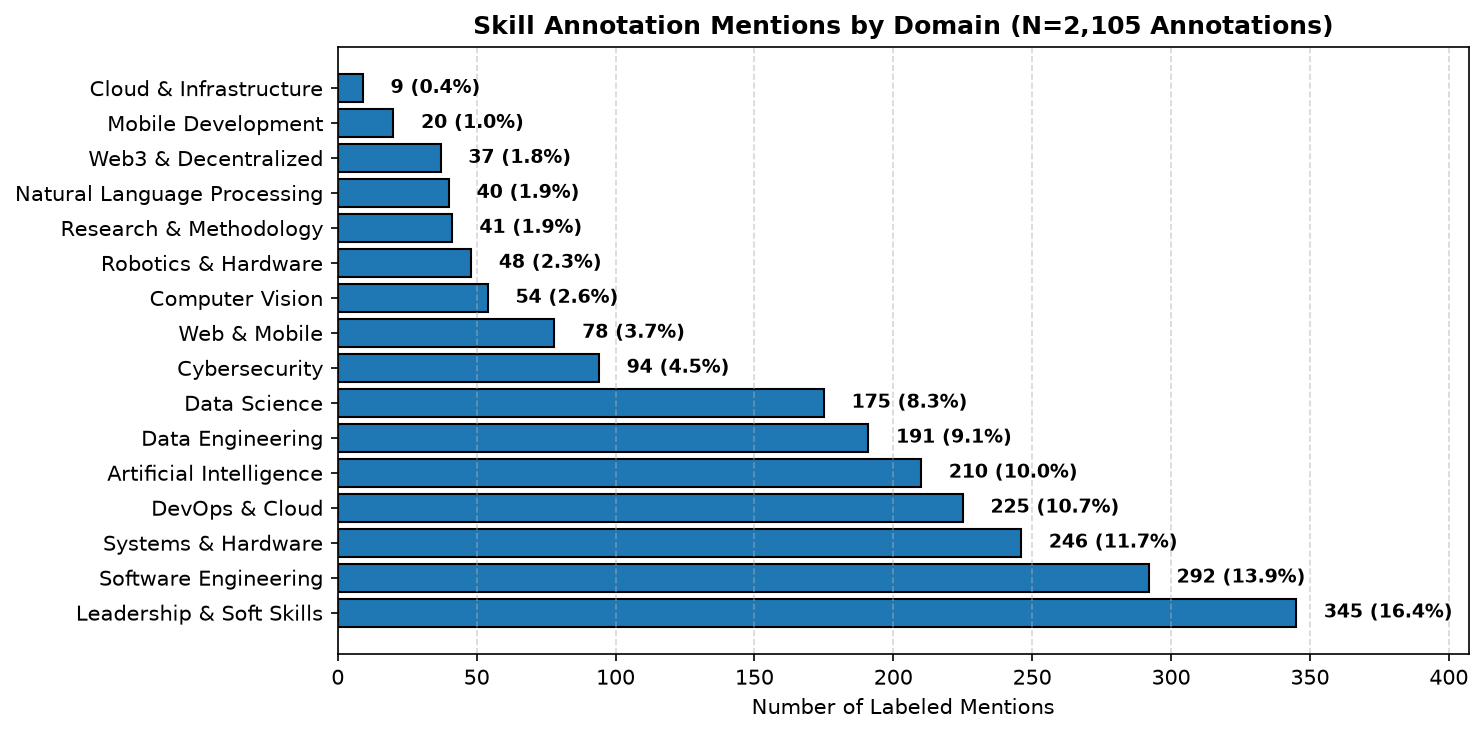

In [5]:
ann_domain_counts = ann_df["skill_domain"].value_counts()

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(ann_domain_counts.index, ann_domain_counts.values, color="#1f77b4", edgecolor="black")

for bar in bars:
    w = bar.get_width()
    ax.text(w + 10, bar.get_y() + bar.get_height()/2, f"{int(w):,} ({w/len(ann_df):.1%})", va="center", fontsize=9, fontweight="bold")

ax.set_title("Skill Annotation Mentions by Domain (N=2,105 Annotations)", fontsize=12, fontweight="bold")
ax.set_xlabel("Number of Labeled Mentions")
ax.set_xlim(0, max(ann_domain_counts.values) * 1.18)
ax.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()